# Aufgabe 1.3 – Integraloperator

$$\mathcal{L}[x](t) = \int_{-1}^{1} \frac{x(s)}{1+(s-t)^2}\,\mathrm{d}s = y(t), \qquad x \in C[-1,1]$$

**Idee:** Wir diskretisieren $s$ und $t$ auf demselben Gitter und approximieren das Integral mit der Trapezregel. Dann wird $\mathcal{L}$ zu einer Matrix $K \in \mathbb{R}^{n\times n}$ und $y = K\,x$ (wie im Beispiel zu den linearen Operatoren).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

## Diskretisierung

In [2]:
n = 401
s = np.linspace(-1, 1, n)   # Integrationsvariable
t = s.copy()                # Auswertungspunkte

# Trapezgewichte
w = np.full(n, s[1] - s[0])
w[0] /= 2
w[-1] /= 2

Matrix des Operators: $K_{ij} = \dfrac{w_j}{1+(s_j-t_i)^2}$, also $y_i \approx \sum_j K_{ij}\,x(s_j)$.

In [3]:
K = w[None, :] / (1 + (s[None, :] - t[:, None])**2)
K.shape

(401, 401)

## 1. Berechnung und Visualisierung

In [4]:
x_a = -s
x_b = np.abs(s)

y_a = K @ x_a
y_b = K @ x_b

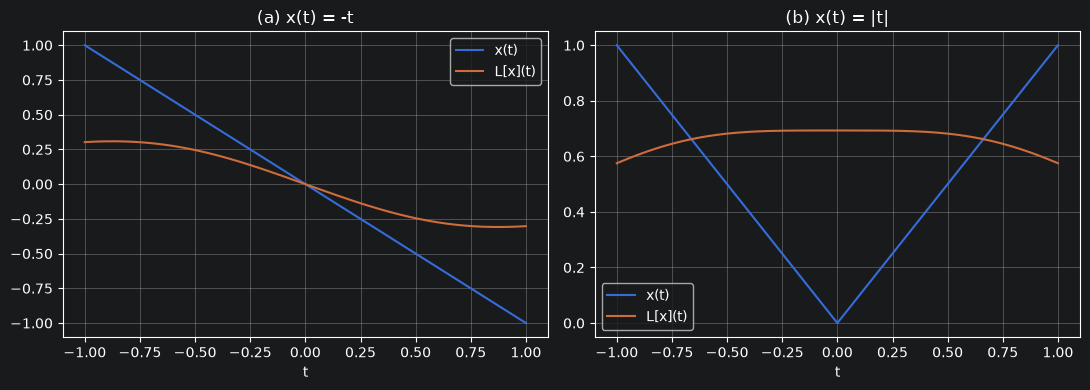

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for a, x, y, name in zip(ax, [x_a, x_b], [y_a, y_b], ["(a) x(t) = -t", "(b) x(t) = |t|"]):
    a.plot(t, x, label="x(t)")
    a.plot(t, y, label="L[x](t)")
    a.set_title(name)
    a.set_xlabel("t")
    a.legend()
    a.grid(True)

plt.tight_layout()
plt.show()

## Kontrolle

**(a)** Geschlossene Lösung (Substitution $u = s-t$):

$$y(t) = -\left[\tfrac12 \ln\frac{1+(1-t)^2}{1+(1+t)^2} + t\,\big(\arctan(1-t)+\arctan(1+t)\big)\right]$$

In [6]:
y_a_exakt = -(0.5*np.log((1 + (1 - t)**2) / (1 + (1 + t)**2))
              + t*(np.arctan(1 - t) + np.arctan(1 + t)))

print("max. Fehler (a):", np.max(np.abs(y_a - y_a_exakt)))

max. Fehler (a): 2.0000054670732403e-06


**(b)** Vergleich mit `scipy.integrate.quad` (Knick bei $s=0$ als Unterteilungspunkt):

In [7]:
y_b_quad = np.array([
    quad(lambda u: abs(u) / (1 + (u - ti)**2), -1, 1, points=[0])[0]
    for ti in t
])

print("max. Fehler (b):", np.max(np.abs(y_b - y_b_quad)))

max. Fehler (b): 4.1666796871675515e-06


## Operatornorm (Vorgriff auf Teil 2)

Bezüglich der Supremumsnorm entspricht die Operatornorm der max-(Zeilensummen-)Norm der Matrix. Theoretisch erwarten wir $\|\mathcal{L}\| = \pi/2 \approx 1.5708$.

In [8]:
print("||K||_inf =", np.linalg.norm(K, np.inf))
print("pi/2      =", np.pi/2)

||K||_inf = 1.5707942434615645
pi/2      = 1.5707963267948966
